In [1]:
import json
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, load_digits
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score
import warnings
from itertools import product
import xgboost as xgb

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 4)

URL_VIAJES = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

In [2]:
df_viajes = pd.read_parquet(URL_VIAJES)

In [3]:
df_zonas= pd.read_csv(URL_ZONAS)

In [4]:
df_viajes.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [5]:
df_viajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [6]:
df_zonas[df_zonas['LocationID']==265]

,LocationID,Borough,Zone,service_zone
264,265,NaN,Outside of NYC,NaN


In [7]:
df_viajes["tpep_pickup_datetime"] = pd.to_datetime(df_viajes["tpep_pickup_datetime"])
df_viajes["mes"] = df_viajes["tpep_pickup_datetime"].dt.to_period("M")

# Si el archivo trae viajes sueltos de otros meses, se queda el mes principal


In [8]:
df_viajes["mes"].value_counts()

,count
mes,
2024-01,2964606
2023-12,10
2009-01,3
2024-02,3
2002-12,2


In [9]:
df_viajes=df_viajes[df_viajes["mes"]=='2024-01']
df_pronostico_futuro=df_viajes[df_viajes["mes"]=='2024-02']


In [10]:
ZONAS_EXCLUIDAS = [264, 265]

In [11]:
viajes=df_viajes.copy()
viajes["timestamp"] = viajes["tpep_pickup_datetime"].dt.floor("h")
viajes = viajes[(viajes["timestamp"] >= "2024-01-01") & (viajes["timestamp"] < "2024-02-01")]
viajes = viajes[~viajes["PULocationID"].isin(ZONAS_EXCLUIDAS)]

In [12]:
conteo_viajes = viajes.groupby(["PULocationID", "timestamp"]).size().rename("viajes")

In [13]:

total_por_zona = conteo_viajes.groupby("PULocationID").sum()
total_por_zona
zonas = total_por_zona[total_por_zona >= 3000].index

In [14]:
horas_enero = pd.date_range("2024-01-01 00:00", "2024-01-31 23:00", freq="h")
idx = pd.MultiIndex.from_product([zonas, horas_enero], names=["PULocationID", "timestamp"])
serie = conteo_viajes.reindex(idx, fill_value=0).reset_index()

# Horas del 1 de febrero vacías
horas_feb = pd.date_range("2024-02-01 00:00", "2024-02-01 23:00", freq="h")
idx_fut = pd.MultiIndex.from_product([zonas, horas_feb], names=["PULocationID", "timestamp"])
futuro_vacio = idx_fut.to_frame(index=False).assign(viajes=np.nan)


In [15]:
#unificación de la serie
serie = pd.concat([serie, futuro_vacio], ignore_index=True)
serie = serie.sort_values(["PULocationID", "timestamp"]).reset_index(drop=True)

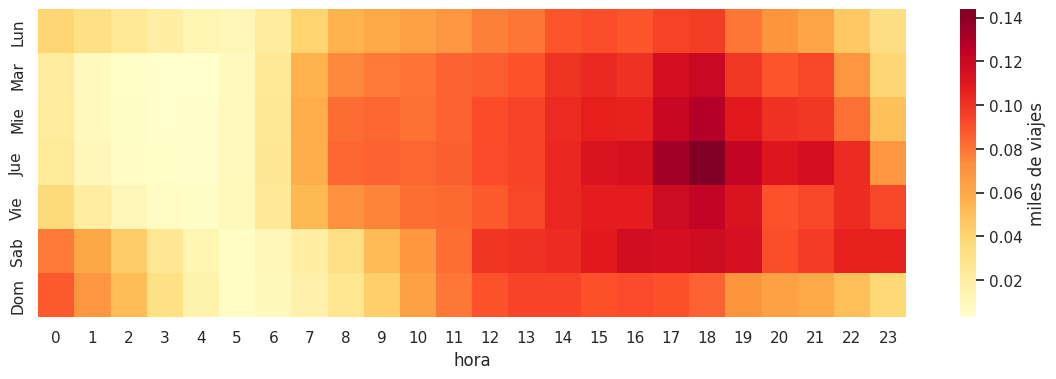

In [16]:
calendario = pd.DataFrame({"pasajeros": serie['viajes'], "dia_semana": serie['timestamp'].dt.dayofweek, "hora": serie['timestamp'].dt.hour})
calendario
mapa = calendario.pivot_table(index='dia_semana', columns='hora', values='pasajeros', aggfunc='mean')
mapa
mapa.index = ["Lun", "Mar", "Mie", "Jue", "Vie", "Sab", 'Dom']
mapa
sns.heatmap(mapa/1000, cmap="YlOrRd", cbar_kws={"label": "miles de viajes"})
plt.show()

In [17]:
temporal = serie.set_index(
    pd.to_datetime(serie["timestamp"])
)["viajes"].sort_index()
temporal

,viajes
timestamp,
2024-01-01 00:00:00,25.0
2024-01-01 00:00:00,30.0
2024-01-01 00:00:00,70.0
2024-01-01 00:00:00,186.0
2024-01-01 00:00:00,22.0
...,...
2024-02-01 23:00:00,NaN
2024-02-01 23:00:00,NaN
2024-02-01 23:00:00,NaN


In [18]:
dias_con_viajes = temporal.groupby(temporal.index.normalize()).sum().gt(0).sum()
print("Días con viajes:", dias_con_viajes)

Días con viajes: 31


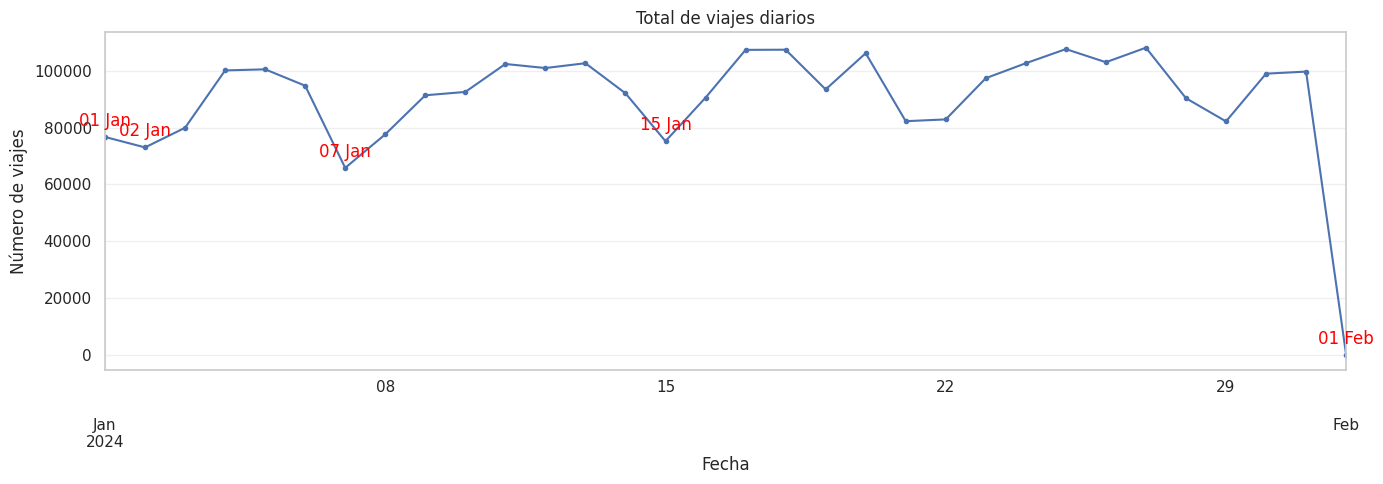

In [19]:
temporal = serie.set_index(
    pd.to_datetime(serie["timestamp"])
)["viajes"].sort_index()

# Calcular los viajes diarios
diario = temporal.resample("D").sum()

plt.figure(figsize=(14, 5))
diario.plot(marker=".")

# Anotar los 5 días con menos viajes
for fecha in diario.nsmallest(5).index:
    plt.annotate(
        fecha.strftime("%d %b"),
        (fecha, diario.loc[fecha]),
        color="red",
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("Total de viajes diarios")
plt.xlabel("Fecha")
plt.ylabel("Número de viajes")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

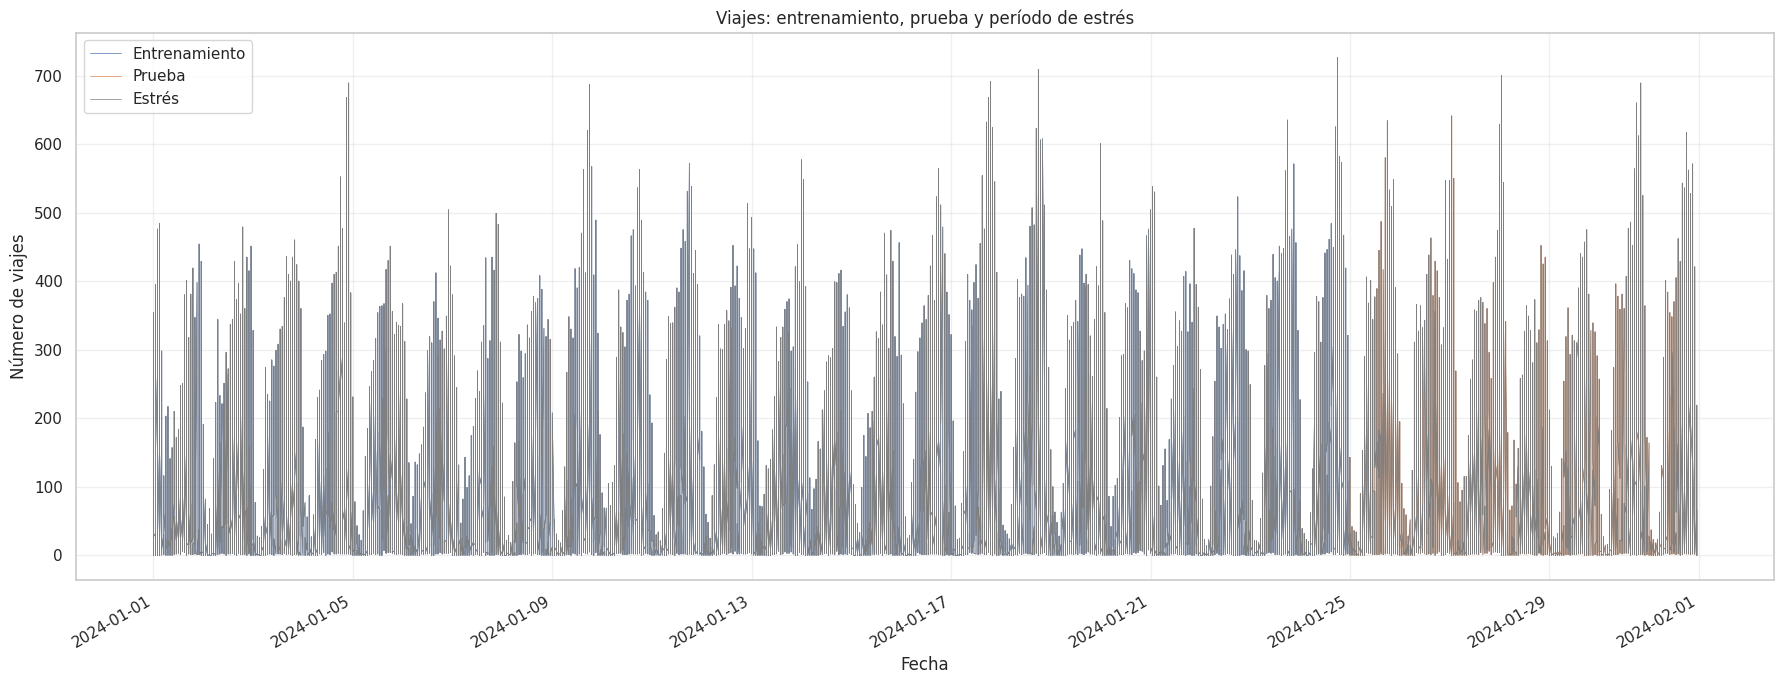

In [20]:
temporal = pd.Series(
    serie["viajes"].to_numpy(),
    index=pd.to_datetime(serie["timestamp"])
).sort_index()

# Definir los períodos (ajusta las fechas según tus datos)
FIN_ENTRENO = "2024-01-24"
INICIO_PRUEBA = "2024-01-25"
FIN_PRUEBA = "2024-01-31"

# Graficar los períodos
fig, ax = plt.subplots(figsize=(18, 7))
temporal.loc[:FIN_ENTRENO].plot(
    linewidth=0.5,
    label="Entrenamiento"
)

temporal.loc[INICIO_PRUEBA:FIN_PRUEBA].plot(
    linewidth=0.5,
    label="Prueba"
)

temporal.loc["2014-12-22":].plot(
    linewidth=0.5,
    color="gray",
    label="Estrés"
)

plt.title("Viajes: entrenamiento, prueba y período de estrés")
plt.xlabel("Fecha")
plt.ylabel("Número de viajes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:


# Crear una copia de trabajo
df_temp = serie[["timestamp", "PULocationID", "viajes"]].copy()

df_temp["timestamp"] = pd.to_datetime(df_temp["timestamp"])

# Agrupar por zona y timestamp
serie_zonas = (
    df_temp.groupby(["PULocationID", "timestamp"])["viajes"]
    .sum()
    .sort_index()
)

# Seleccionar una zona para evaluar
zona_id = 263

temporal = serie_zonas.loc[zona_id].sort_index()

# Datos reales del período de prueba
real = temporal.loc[INICIO_PRUEBA:FIN_PRUEBA]

# Pronósticos ingenuos
ingenuos = pd.DataFrame(index=real.index)

ingenuos["promedio"] = temporal.loc[:FIN_ENTRENO].mean()
ingenuos["ingenuo_diario"] = temporal.shift(24).reindex(real.index)
ingenuos["ingenuo_semanal"] = temporal.shift(168).reindex(real.index)

ingenuos["real"] = real

ingenuos.head(10)

,promedio,ingenuo_diario,ingenuo_semanal,real
timestamp,,,,
2024-01-25 00:00:00,78.642361,18.0,19.0,18.0
2024-01-25 01:00:00,78.642361,19.0,11.0,15.0
2024-01-25 02:00:00,78.642361,6.0,2.0,3.0
2024-01-25 03:00:00,78.642361,3.0,3.0,3.0
2024-01-25 04:00:00,78.642361,4.0,1.0,8.0
2024-01-25 05:00:00,78.642361,13.0,16.0,19.0
2024-01-25 06:00:00,78.642361,43.0,58.0,50.0
2024-01-25 07:00:00,78.642361,127.0,125.0,128.0
2024-01-25 08:00:00,78.642361,129.0,172.0,149.0


In [22]:
errores = {nombre: mean_absolute_error(real, ingenuos[nombre]) for nombre in ingenuos}

In [23]:
errores

{'promedio': 45.02393353174604,
 'ingenuo_diario': 22.11904761904762,
 'ingenuo_semanal': 12.166666666666666,
 'real': 0.0}

In [24]:
df_temp = serie[["timestamp", "viajes"]].copy()
df_temp["timestamp"] = pd.to_datetime(df_temp["timestamp"])

# Sumar los viajes de todas las zonas por timestamp
serie_temporal = (
    df_temp.groupby("timestamp")["viajes"]
    .sum()
    .sort_index()
)


serie_temporal = serie_temporal.resample("h").sum()

entrenamiento = serie_temporal.loc[:FIN_ENTRENO]
real = serie_temporal.loc[INICIO_PRUEBA:FIN_PRUEBA]

# Crear pronósticos
ingenuos = pd.DataFrame(index=real.index)

ingenuos["promedio"] = entrenamiento.mean()

ingenuos["ingenuo_diario"] = (
    serie_temporal.shift(24).reindex(real.index)
)

ingenuos["ingenuo_semanal"] = (
    serie_temporal.shift(168).reindex(real.index)
)

ingenuos["real"] = real

# Calcular errores generales
resultados = []

for modelo in ["promedio", "ingenuo_diario", "ingenuo_semanal"]:

    comparacion = ingenuos[["real", modelo]].dropna()

    y_real = comparacion["real"]
    y_pred = comparacion[modelo]

    resultados.append({
        "Modelo": modelo,
        "MAE": np.mean(np.abs(y_real - y_pred)),
        "RMSE": np.sqrt(np.mean((y_real - y_pred) ** 2)),
        "WAPE (%)": (
            np.sum(np.abs(y_real - y_pred)) / np.sum(y_real) * 100
            if np.sum(y_real) != 0 else np.nan
        )
    })

metricas_globales = pd.DataFrame(resultados)

metricas_globales

,Modelo,MAE,RMSE,WAPE (%)
0,promedio,2081.330605,2329.299095,50.673158
1,ingenuo_diario,760.142857,1242.132656,18.506834
2,ingenuo_semanal,278.202381,400.968574,6.773260


In [25]:
#Modelo
# Variables
g = serie.groupby("PULocationID")["viajes"]
for k in [24, 48, 167, 168, 169]:
    serie[f"lag_{k}"] = g.shift(k)

# Promedio de viajes por hora del día anterior (por zona)
serie["fecha"] = serie["timestamp"].dt.floor("D")
media_dia = (serie.groupby(["PULocationID", "fecha"])["viajes"].mean()
             .rename("media_dia_ant").reset_index())
media_dia["fecha"] += pd.Timedelta(days=1)
serie = serie.merge(media_dia, on=["PULocationID", "fecha"], how="left")

In [26]:
serie.head()

,PULocationID,timestamp,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,fecha,media_dia_ant
0,4,2024-01-01 00:00:00,25.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN
1,4,2024-01-01 01:00:00,29.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN
2,4,2024-01-01 02:00:00,34.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN
3,4,2024-01-01 03:00:00,31.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN
4,4,2024-01-01 04:00:00,32.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN


In [27]:
serie["hora"] = serie["timestamp"].dt.hour
serie["dia_semana"] = serie["timestamp"].dt.dayofweek
serie["feriado"] = (serie["fecha"] == "2024-01-15").astype(int)

# Zona en todos apartados de tiempo
serie["zona"] = pd.Categorical(serie["PULocationID"], categories=sorted(zonas))

In [28]:
serie.head()

,PULocationID,timestamp,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,fecha,media_dia_ant,hora,dia_semana,feriado,zona
0,4,2024-01-01 00:00:00,25.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,0,0,0,4
1,4,2024-01-01 01:00:00,29.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,1,0,0,4
2,4,2024-01-01 02:00:00,34.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,2,0,0,4
3,4,2024-01-01 03:00:00,31.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,3,0,0,4
4,4,2024-01-01 04:00:00,32.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,4,0,0,4


In [29]:
FEATURES = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169",
            "media_dia_ant", "hora", "dia_semana", "feriado", "zona"]

# Hacer partición
f_train = pd.Timestamp("2024-01-25")
f_futuro = pd.Timestamp("2024-02-01")

train = serie[serie["timestamp"] < f_train].dropna()
test = serie[(serie["timestamp"] >= f_train) & (serie["timestamp"] < f_futuro)].dropna()
futuro = serie[serie["timestamp"] >= f_futuro]

In [30]:
cuantiles = np.round(np.arange(0.1, 0.91, 0.1), 1)
i50 = int(np.argmin(np.abs(cuantiles - 0.5)))
i10, i90 = 0, len(cuantiles) - 1
params_base = dict(
    objective="reg:quantileerror", quantile_alpha=cuantiles,
    tree_method="hist", enable_categorical=True,
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42,
)

In [31]:

#Pruebas de parametros
def pinball(y, pred, qs):
    """Pérdida pinball promedio sobre todos los cuantiles."""
    d = y[:, None] - pred
    return np.mean(np.maximum(qs * d, (qs - 1) * d))

# Folds por tiempo: entrena antes del corte y valida los 3 días siguientes (sin tocar la prueba)
cortes = pd.to_datetime(["2024-01-17", "2024-01-20", "2024-01-23"])
folds = [(c, min(c + pd.Timedelta(days=3), f_train)) for c in cortes]

# Rejilla pequeña
rejilla = {
    "max_depth": [4, 6],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200, 400],
    "min_child_weight": [1, 10],
}

resultados_cv = []
for valores in product(*rejilla.values()):
    p = dict(zip(rejilla.keys(), valores))
    perdidas = []
    for ini_val, fin_val in folds:
        tr = train[train["timestamp"] < ini_val]
        va = train[(train["timestamp"] >= ini_val) & (train["timestamp"] < fin_val)]
        m = xgb.XGBRegressor(**{**params_base, **p}).fit(tr[FEATURES], tr["viajes"])
        pr = np.sort(m.predict(va[FEATURES]), axis=1).clip(min=0)
        perdidas.append(pinball(va["viajes"].to_numpy(), pr, cuantiles))
    resultados_cv.append({**p, "pinball_cv": np.mean(perdidas)})

resultados_cv = pd.DataFrame(resultados_cv).sort_values("pinball_cv")
print(resultados_cv.head())

mejores = resultados_cv.iloc[0].drop("pinball_cv").to_dict()
mejores["max_depth"] = int(mejores["max_depth"])
mejores["n_estimators"] = int(mejores["n_estimators"])
mejores["min_child_weight"] = int(mejores["min_child_weight"])


params = {**params_base, **mejores}

KeyboardInterrupt: 

In [ ]:
y = test["viajes"].to_numpy()

def evaluar(parametros):
    m = xgb.XGBRegressor(**parametros).fit(train[FEATURES], train["viajes"])
    pr = np.sort(m.predict(test[FEATURES]), axis=1).clip(min=0)
    return pr

pred_base = evaluar(params_base)
pred = evaluar(params)

resultados = pd.DataFrame({
    "modelo": ["XGBoost ajustado (p50)", "XGBoost base (p50)",
               "igual que hace una semana (lag_168)", "igual que ayer (lag_24)"],
    "MAE": [
        np.mean(np.abs(y - pred[:, i50])),
        np.mean(np.abs(y - pred_base[:, i50])),
        np.mean(np.abs(y - test["lag_168"])),
        np.mean(np.abs(y - test["lag_24"])),
    ],
})
print(resultados.round(2))
print(f"Pinball prueba (ajustado): {pinball(y, pred, cuantiles):.3f}")
print(f"Pinball prueba (base):     {pinball(y, pred_base, cuantiles):.3f}")
print(f"Cobertura p10-p90 (ajustado): {np.mean((y >= pred[:, i10]) & (y <= pred[:, i90])):.1%} (ideal ≈ 80%)")


                                modelo    MAE
0               XGBoost ajustado (p50)  11.60
1                   XGBoost base (p50)  11.60
2  igual que hace una semana (lag_168)  11.88
3              igual que ayer (lag_24)  21.29
Pinball prueba (ajustado): 4.535
Pinball prueba (base):     4.535
Cobertura p10-p90 (ajustado): 83.8% (ideal ≈ 80%)


In [32]:


cuantiles = np.round(np.arange(0.1, 0.91, 0.1), 1)

params = dict(
    objective="reg:quantileerror", quantile_alpha=cuantiles,
    tree_method="hist", enable_categorical=True,
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42,
)
modelo = xgb.XGBRegressor(**params)
modelo.fit(train[FEATURES], train["viajes"])

pred = np.sort(modelo.predict(test[FEATURES]), axis=1).clip(min=0)


In [33]:
# Validación temporal: los últimos días de train (ajusta a tu columna de fecha)
corte = train["fecha"].max() - pd.Timedelta(days=7)
tr, va = train[train["fecha"] <= corte], train[train["fecha"] > corte]

diag = xgb.XGBRegressor(**{**params, "n_estimators": 1000})
diag.fit(tr[FEATURES], tr["viajes"],
         eval_set=[(va[FEATURES], va["viajes"])], verbose=False)

curva = diag.evals_result()["validation_0"]
metrica = list(curva)[0]
mejor = int(np.argmin(curva[metrica])) + 1
print(f"Mejor iteración en validación: {mejor} de 1000")

Mejor iteración en validación: 326 de 1000


In [34]:
i50 = int(np.argmin(np.abs(cuantiles - 0.5)))
i10, i90 = 0, len(cuantiles) - 1
y = test["viajes"].to_numpy()

resultados = pd.DataFrame({
    "modelo": ["XGBoost p50", "igual que hace una semana (lag_168)", "igual que ayer (lag_24)"],
    "MAE": [
        np.mean(np.abs(y - pred[:, i50])),
        np.mean(np.abs(y - test["lag_168"])),
        np.mean(np.abs(y - test["lag_24"])),
    ],
})
cobertura = np.mean((y >= pred[:, i10]) & (y <= pred[:, i90]))
print(resultados.round(2))
print(f"Cobertura de la banda p10-p90: {cobertura:.1%} (ideal aprx 80%)")


                                modelo    MAE
0                          XGBoost p50  11.60
1  igual que hace una semana (lag_168)  11.88
2              igual que ayer (lag_24)  21.29
Cobertura de la banda p10-p90: 83.8% (ideal aprx 80%)


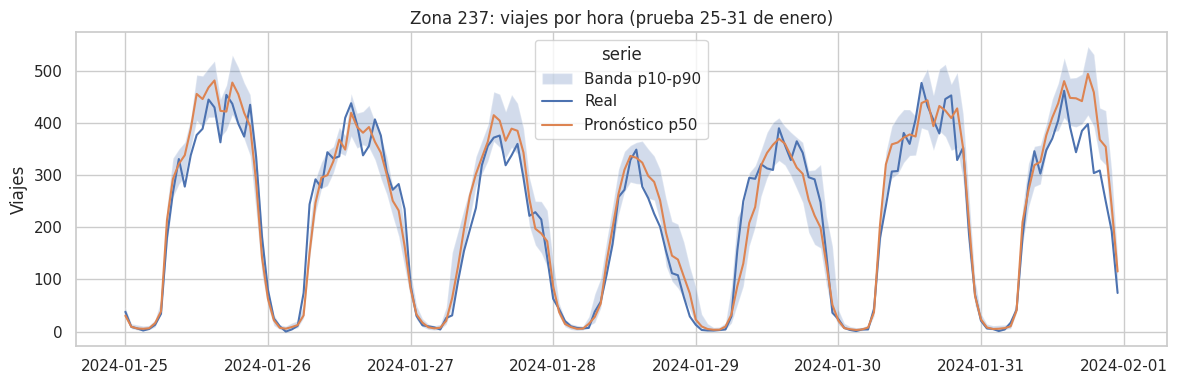

In [35]:
zona_ej = test.groupby("PULocationID")["viajes"].sum().idxmax()
m = (test["PULocationID"] == zona_ej).to_numpy()
graf = pd.DataFrame({"timestamp": test.loc[m, "timestamp"], "Real": y[m], "Pronóstico p50": pred[m, i50]})

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(graf["timestamp"], pred[m, i10], pred[m, i90], alpha=0.25, label="Banda p10-p90")
sns.lineplot(data=graf.melt("timestamp", var_name="serie", value_name="viajes"),
             x="timestamp", y="viajes", hue="serie", ax=ax)
ax.set(title=f"Zona {zona_ej}: viajes por hora (prueba 25-31 de enero)", xlabel="", ylabel="Viajes")
plt.tight_layout()
plt.show()

In [36]:
final = pd.concat([train])
modelo_final = xgb.XGBRegressor(**params).fit(final[FEATURES], final["viajes"])

pred_fut = np.sort(modelo_final.predict(futuro[FEATURES]), axis=1).clip(min=0)
pronostico = futuro[["PULocationID", "timestamp"]].reset_index(drop=True).copy()
for j, q in enumerate(cuantiles):
    pronostico[f"p{int(q * 100)}"] = pred_fut[:, j]

In [ ]:
pronostico

,PULocationID,timestamp,p10,p20,p30,p40,p50,p60,p70,p80,p90
0,4,2024-02-01 00:00:00,0.000000,0.506399,0.806620,0.901085,1.559251,2.185136,3.104048,4.679206,7.591079
1,4,2024-02-01 01:00:00,0.000000,0.556505,0.645841,1.049697,1.061661,1.441236,2.609950,3.645127,6.765891
2,4,2024-02-01 02:00:00,0.000000,0.000000,0.060699,0.147646,0.429321,0.833991,1.127078,2.374748,5.192801
3,4,2024-02-01 03:00:00,0.000000,0.000000,0.000000,0.076066,0.218883,0.570762,0.972424,1.973195,5.081455
4,4,2024-02-01 04:00:00,0.000000,0.000000,0.000000,0.076066,0.329876,0.570762,0.997661,1.990105,5.081455
...,...,...,...,...,...,...,...,...,...,...,...
1387,263,2024-02-01 19:00:00,95.623337,101.050072,105.401817,108.799950,115.181374,116.410324,123.145844,129.400101,136.271759
1388,263,2024-02-01 20:00:00,97.780876,106.442719,110.924850,114.660614,119.553680,120.160599,122.648254,126.388588,133.140411
1389,263,2024-02-01 21:00:00,89.827148,99.136314,102.925171,107.686836,113.729652,115.803635,118.986176,120.726616,124.427162
1390,263,2024-02-01 22:00:00,74.818169,85.541313,92.915619,99.036644,102.398460,103.127220,106.774834,113.665298,117.586617


In [38]:
import json
import joblib
joblib.dump(modelo_final, "modelo_viajes.joblib")
with open("info_modelo_viajes.json", "w") as f:
    json.dump({
        "variables": FEATURES,
        "cuantiles": [float(q) for q in cuantiles],
        "zonas": [int(z) for z in sorted(zonas)],
        "zonas_excluidas": ZONAS_EXCLUIDAS,
    }, f, ensure_ascii=False, indent=2)

In [ ]:

files.download("modelo_viajes.joblib")
files.download("info_modelo_viajes.json")

In [39]:
import os
import shutil


carpeta = "/content/api"
os.makedirs(carpeta, exist_ok=True)

# Modelo entrenado solo hasta el 24 de enero
modelo_final.save_model(f"{carpeta}/modelo_pronostico.ubj")

# Nombre y distrito de cada zona (ajusta los nombres de columna si tu df_zonas usa otros)
nombres = (df_zonas[["LocationID", "Zone", "Borough"]]
           .rename(columns={"LocationID": "PULocationID", "Zone": "nombre", "Borough": "distrito"}))

# Horas del 25 de enero al 1 de febrero, con las variables ya calculadas
demanda = (serie[serie["timestamp"] >= "2024-01-25"]
           .drop(columns="zona")
           .merge(nombres, on="PULocationID", how="left")
           .reset_index(drop=True))
demanda.to_parquet(f"{carpeta}/demanda.parquet", index=False)

# Verificaciones
print("Zonas sin nombre:", demanda["nombre"].isna().sum())
print("Versión de xgboost (fíjala en requirements.txt):", xgb.__version__)

chk = xgb.XGBRegressor()
chk.load_model(f"{carpeta}/modelo_pronostico.ubj")
d = demanda.copy()
d["zona"] = pd.Categorical(d["PULocationID"], categories=sorted(zonas))
dif = np.abs(chk.predict(d[FEATURES]) - modelo.predict(d[FEATURES])).max()
print("Diferencia máxima modelo guardado vs original:", dif)  # debe ser ~0

# Comprimir y descargar
shutil.make_archive("/content/api_pronostico", "zip", carpeta)
files.download("/content/api_pronostico.zip")

Zonas sin nombre: 0
Versión de xgboost (fíjala en requirements.txt): 3.4.1
Diferencia máxima modelo guardado vs original: 0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import shutil
import xgboost
from google.colab import files

carpeta = "/content/api"
os.makedirs(carpeta, exist_ok=True)

#main.py
codigo_main = r'''from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb
from fastapi import FastAPI, HTTPException

BASE = Path(__file__).parent

VARIABLES = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169",
             "media_dia_ant", "hora", "dia_semana", "feriado", "zona"]
CUANTILES = np.round(np.arange(0.1, 0.91, 0.1), 1)
NOMBRES_Q = [f"p{int(round(q * 100))}" for q in CUANTILES]

modelo = xgb.XGBRegressor()
modelo.load_model(BASE / "modelo_pronostico.ubj")

demanda = pd.read_parquet(BASE / "demanda.parquet")
demanda["dia"] = demanda["timestamp"].dt.date
demanda["nombre"] = demanda["nombre"].fillna("Zona " + demanda["PULocationID"].astype(str))
demanda["distrito"] = demanda["distrito"].fillna("Sin distrito")
# Mismas categorías (y mismo orden) que en el entrenamiento
DTIPO_ZONA = "int64"

ids = sorted(int(z) for z in demanda["PULocationID"].unique())
demanda["zona"] = pd.Categorical(
    demanda["PULocationID"].astype(DTIPO_ZONA),
    categories=pd.Index(ids, dtype=DTIPO_ZONA),

FECHAS = sorted(str(d) for d in demanda["dia"].unique())

app = FastAPI(title="API de pronóstico de demanda - Taxis NYC")


@app.get("/")
def raiz():
    return {"estado": "en línea"}


@app.get("/info")
def info():
    zonas = (demanda[["PULocationID", "nombre", "distrito"]]
             .drop_duplicates().sort_values("nombre"))
    return {
        "zonas": [{"id": int(r.PULocationID), "nombre": r.nombre, "distrito": r.distrito}
                  for r in zonas.itertuples()],
        "fechas": FECHAS,
        "cuantiles": NOMBRES_Q,
    }


@app.get("/pronostico")
def pronostico(zona_id: int, fecha: date):
    filas = (demanda[(demanda["PULocationID"] == zona_id) & (demanda["dia"] == fecha)]
             .sort_values("timestamp"))
    if filas.empty:
        raise HTTPException(status_code=404, detail="No hay datos para esa zona o fecha")

    q = np.sort(modelo.predict(filas[VARIABLES]), axis=1).clip(min=0)

    horas = []
    for i, (_, f) in enumerate(filas.iterrows()):
        horas.append({
            "hora": int(f["hora"]),
            "real": None if pd.isna(f["viajes"]) else int(f["viajes"]),
            "hace_una_semana": None if pd.isna(f["lag_168"]) else int(f["lag_168"]),
            "cuantiles": {n: round(float(v), 1) for n, v in zip(NOMBRES_Q, q[i])},
        })

    return {
        "zona": {"id": int(zona_id), "nombre": filas["nombre"].iloc[0],
                 "distrito": filas["distrito"].iloc[0]},
        "fecha": str(fecha),
        "horas": horas,
    }
'''
with open(f"{carpeta}/main.py", "w", encoding="utf-8") as f:
    f.write(codigo_main)

# requirements.txt
requisitos = f"""fastapi
uvicorn[standard]
pandas
pyarrow
numpy
scikit-learn
xgboost=={xgboost.__version__}
"""
with open(f"{carpeta}/requirements.txt", "w", encoding="utf-8") as f:
    f.write(requisitos)

# ---------- Revisar y descargar ----------
print(sorted(os.listdir(carpeta)))
print(requisitos)

shutil.make_archive("/content/api_pronostico", "zip", carpeta)
files.download("/content/api_pronostico.zip")

In [ ]:
import xgboost
print("xgboost en Colab:", xgboost.__version__)
print("dtype categorías de zona:", train["zona"].cat.categories.dtype)

**DESICION**

In [40]:
costo_ocioso, costo_perdido = 10, 40
q_opt = costo_perdido / (costo_perdido + costo_ocioso)

def costo(enviados, real):
    return (np.maximum(enviados - real, 0) * costo_ocioso
            + np.maximum(real - enviados, 0) * costo_perdido)

t = test.reset_index(drop=True)
mask = ((t["PULocationID"] == 161) &
        (t["timestamp"].dt.date == pd.Timestamp("2024-01-31").date())).to_numpy()

real = t.loc[mask, "viajes"].to_numpy()
pred_dia = pred[mask]

env_rec = np.round([np.interp(q_opt, cuantiles, fila) for fila in pred_dia])
env_p50 = np.round(pred_dia[:, i50])
env_sem = t.loc[mask, "lag_168"].to_numpy()

resultado = pd.DataFrame({
    "regla": [f"Recomendación (p{round(q_opt * 100)})", "Pronóstico central (p50)", "Hace una semana"],
    "costo_usd": [costo(env_rec, real).sum(), costo(env_p50, real).sum(), costo(env_sem, real).sum()],
})
resultado["vs_recomendacion_%"] = (resultado["costo_usd"] / resultado.loc[0, "costo_usd"] - 1) * 100
print(resultado.round(1))

                      regla  costo_usd  vs_recomendacion_%
0       Recomendación (p80)     8870.0                 0.0
1  Pronóstico central (p50)    11530.0                30.0
2           Hace una semana    15880.0                79.0


**Segmentación**

In [43]:
# Zona de origen
df = df_viajes.merge(
    df_zonas,
    left_on="PULocationID", right_on="LocationID", how="left"
)

# Zona de destino
df = df.merge(
    df_zonas.add_prefix("DO_"),
    left_on="DOLocationID", right_on="DO_LocationID", how="left"
)

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964606 entries, 0 to 2964605
Data columns (total 28 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [45]:
#Variables
df["duracion"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
df["hora"] = df["tpep_pickup_datetime"].dt.hour
df["dia_semana"] = df["tpep_pickup_datetime"].dt.dayofweek
df["dia"] = df["tpep_pickup_datetime"].dt.day
df["fecha"] = df["tpep_pickup_datetime"].dt.date
df["velocidad"] = df["trip_distance"] / (df["duracion"] / 60)
df["con_peaje"] = (df["tolls_amount"] > 0).astype(int)
df["con_congestion"] = (df["congestion_surcharge"] > 0).astype(int)
df["con_tarjeta"] = (df["payment_type"] == 1).astype(int)
df["misma_zona"] = (df["PULocationID"] == df["DOLocationID"]).astype(int)

In [46]:
df[['duracion','trip_distance','fare_amount']].describe()

,duracion,trip_distance,fare_amount
count,2.964606e+06,2.964606e+06,2.964606e+06
mean,1.561297e+01,3.652170e+00,1.817507e+01
std,3.485115e+01,2.254633e+02,1.894957e+01
min,-1.356667e+01,0.000000e+00,-8.990000e+02
25%,7.150000e+00,1.000000e+00,8.600000e+00
50%,1.163333e+01,1.680000e+00,1.280000e+01
75%,1.868333e+01,3.110000e+00,2.050000e+01
max,9.455400e+03,3.127223e+05,5.000000e+03


In [47]:
# Limpieza
df = df[(df.trip_distance.between(0,100, inclusive='neither'))  & (df["fare_amount"] > 0)]
df = df[(df["duracion"] > 0) & (df["duracion"] <= 180)]
df = df[~df["LocationID"].isin([264, 265])]



In [48]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,duracion,hora,dia_semana,dia,fecha,velocidad,con_peaje,con_congestion,con_tarjeta,misma_zona
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,...,19.800000,0,0,1,2024-01-01,5.212121,0,1,0,0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,...,6.600000,0,0,1,2024-01-01,16.363636,0,1,1,0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,...,17.916667,0,0,1,2024-01-01,15.739535,0,1,1,0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,...,8.300000,0,0,1,2024-01-01,10.120482,0,1,1,0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,...,6.100000,0,0,1,2024-01-01,7.868852,0,1,1,0


In [49]:
#Calculo Variables
df["es_finde"] = (df["tpep_pickup_datetime"].dt.dayofweek >= 5).astype(int)
df["franja_6_10"] = ((df["hora"] >= 6) & (df["hora"] <= 10)).astype(int)
df["franja_16_20"] = ((df["hora"] >= 16) & (df["hora"] <= 20)).astype(int)
df["franja_22_5"] = ((df["hora"] >= 22) | (df["hora"] <= 5)).astype(int)
df["pct_propina"] = np.where(df["payment_type"] == 1,
                               df["tip_amount"] / df["fare_amount"], np.nan)

In [50]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,velocidad,con_peaje,con_congestion,con_tarjeta,misma_zona,es_finde,franja_6_10,franja_16_20,franja_22_5,pct_propina
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,...,5.212121,0,1,0,0,0,0,0,1,NaN
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,...,16.363636,0,1,1,0,0,0,0,1,0.375000
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,...,15.739535,0,1,1,0,0,0,0,1,0.128755
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,...,10.120482,0,1,1,0,0,0,0,1,0.200000
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,...,7.868852,0,1,1,0,0,0,0,1,0.405063


In [51]:
#Agrupaciones por zona
zonas = df.groupby("PULocationID").agg(
    n_viajes=("fare_amount", "count"),
    n_dias=("fecha", "nunique"),
    distancia_mediana=("trip_distance", "median"),
    tarifa_mediana=("fare_amount", "median"),
    propina_mediana=("tip_amount", "median"),
    pct_finde=("es_finde", "mean"),
    pct_6_10=("franja_6_10", "mean"),
    pct_16_20=("franja_16_20", "mean"),
    pct_22_5=("franja_22_5", "mean"),
    duracion_mediana=("duracion", "median"),
    velocidad_mediana=("velocidad", "median"),
    pasajeros_medio=("passenger_count", "mean"),
    pct_peaje=("con_peaje", "mean"),
    pct_congestion=("con_congestion", "mean"),
    pct_tarjeta=("con_tarjeta", "mean"),
    pct_misma_zona=("misma_zona", "mean"),
    propina_pct_mediana=("pct_propina", "median"),
).reset_index()

zonas["viajes_dia"] = zonas["n_viajes"] / zonas["n_dias"]


In [52]:
zonas=zonas[zonas['n_viajes']>=500]

In [53]:
features = ["viajes_dia", "distancia_mediana", "tarifa_mediana", "propina_mediana" ,"duracion_mediana",
            "pct_finde", "pct_6_10", "pct_16_20", "pct_22_5", "pct_peaje","pct_congestion"]

zonas = zonas.dropna(subset=features).reset_index(drop=True)

In [54]:
zonas.head()

,PULocationID,n_viajes,n_dias,distancia_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5,duracion_mediana,velocidad_mediana,pasajeros_medio,pct_peaje,pct_congestion,pct_tarjeta,pct_misma_zona,propina_pct_mediana,viajes_dia
0,4,3246,31,2.080,14.2,2.44,0.553913,0.126617,0.130314,0.599199,12.183333,10.074466,1.371851,0.007394,0.738139,0.664510,0.016020,0.254237,104.709677
1,7,1497,31,2.960,18.5,0.00,0.332665,0.307281,0.211757,0.195725,15.116667,11.110571,1.207129,0.049432,0.189045,0.353373,0.128925,0.197183,48.290323
2,10,858,31,14.185,70.0,5.00,0.228438,0.275058,0.287879,0.170163,33.991667,22.102158,1.366093,0.463869,0.439394,0.780886,0.033800,0.142857,27.677419
3,12,846,31,4.600,24.7,2.97,0.263593,0.061466,0.289598,0.024823,18.650000,12.674676,1.748489,0.029551,0.969267,0.685579,0.004728,0.231462,27.290323
4,13,15310,31,3.510,19.8,3.65,0.172698,0.159895,0.427694,0.044481,15.333333,13.047228,1.332773,0.049706,0.922469,0.820118,0.020248,0.243478,493.870968


In [55]:
zonas['PULocationID'].value_counts()

,count
PULocationID,
4,1
7,1
10,1
12,1
13,1
...,...
256,1
260,1
261,1


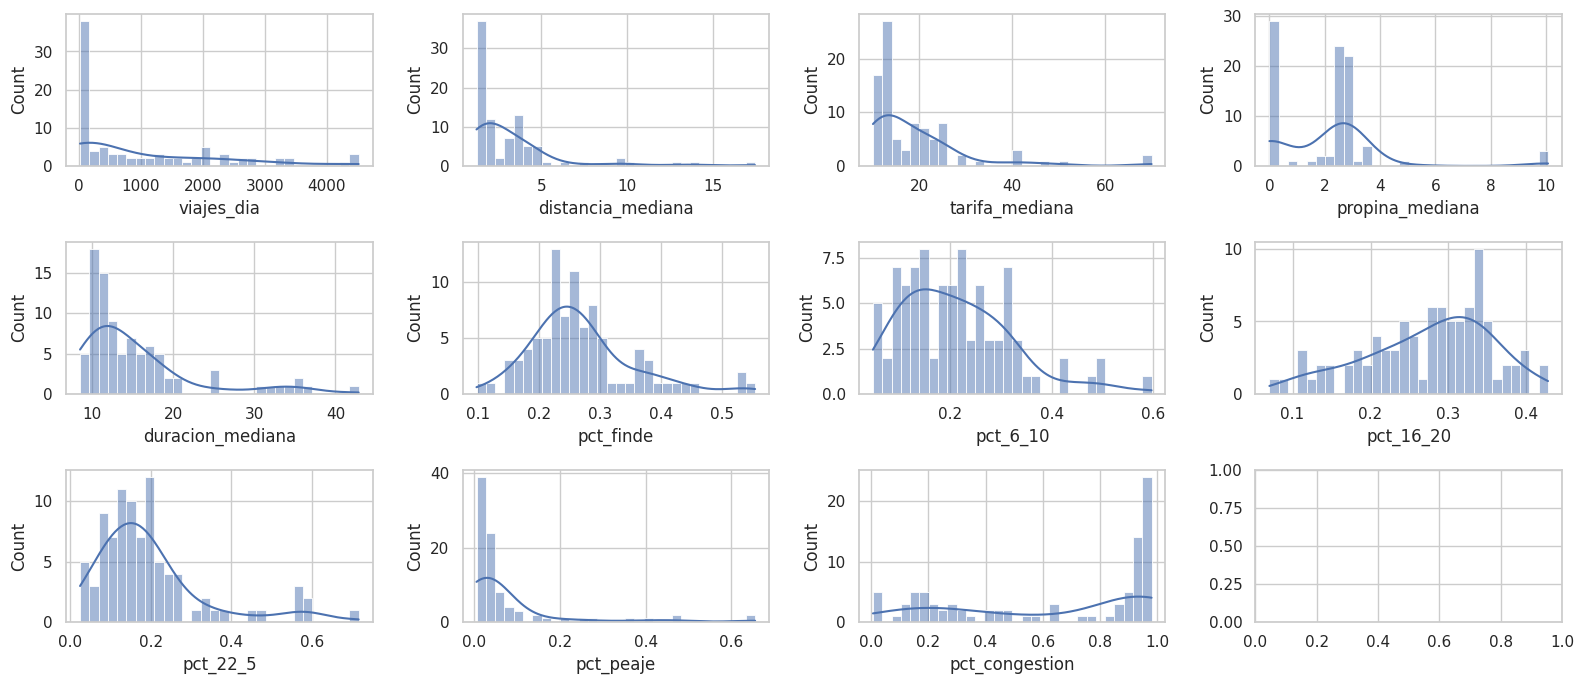

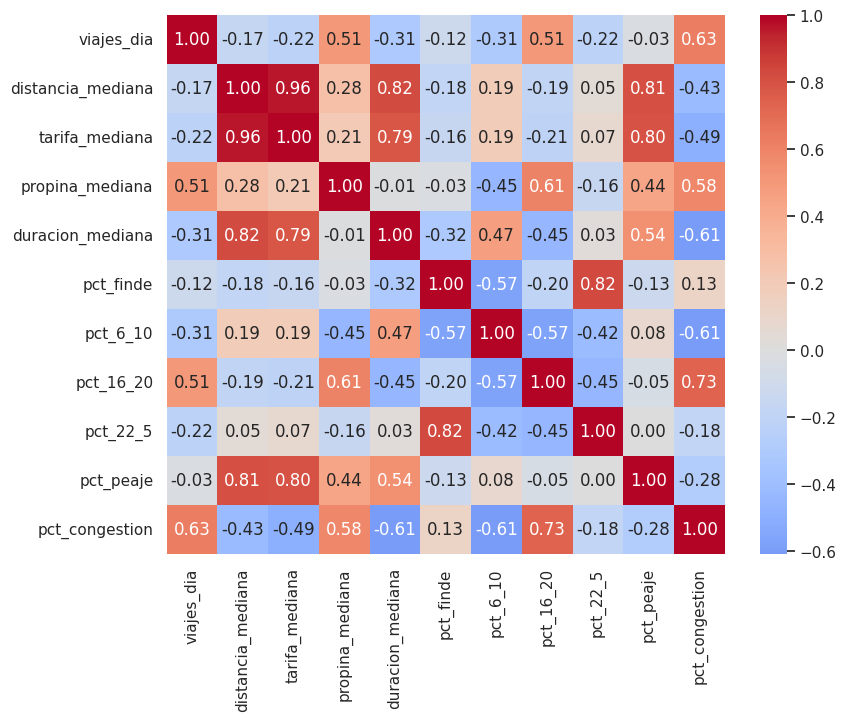

In [56]:
fig, axes = plt.subplots(3, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(zonas[col], bins=30, kde=True, ax=ax)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(zonas[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()



In [57]:
from sklearn.compose import ColumnTransformer
con_log = ["viajes_dia","distancia_mediana", "tarifa_mediana", "propina_mediana", "duracion_mediana"]
sin_log = ["pct_finde","pct_6_10", "pct_16_20", "pct_22_5", "pct_peaje","pct_congestion"]

preparacion = make_pipeline(
    ColumnTransformer([
        ("log", FunctionTransformer(np.log1p), con_log),
        ("igual", "passthrough", sin_log),
    ]),
    StandardScaler(),
)
X = preparacion.fit_transform(zonas[features])

In [58]:
resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    resultados.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(X, km.labels_)})

resultados = pd.DataFrame(resultados)
resultados.round(3)

,k,inercia,silueta
0,2,593.736,0.414
1,3,449.734,0.438
2,4,351.915,0.445
3,5,288.456,0.436
4,6,239.347,0.416
5,7,199.822,0.409
6,8,172.004,0.415


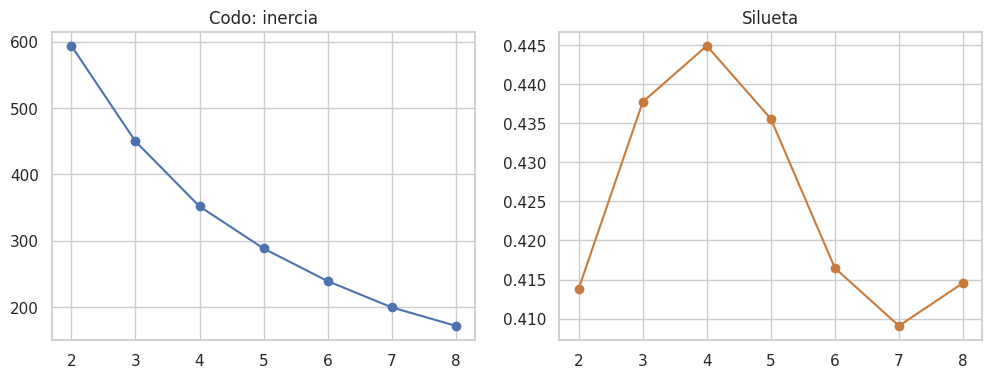

In [59]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4))
izq.plot(resultados["k"], resultados["inercia"], marker="o")
izq.set_title("Codo: inercia")
der.plot(resultados["k"], resultados["silueta"], marker="o", color="#C97B3D")
der.set_title("Silueta")
plt.show()

In [60]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
zonas["segmento"] = km4.labels_
zonas["segmento"].value_counts().sort_index()

,count
segmento,
0,27
1,50
2,5
3,8


In [61]:
perfil = zonas.groupby("segmento")[features].median()
perfil.round(2)

,viajes_dia,distancia_mediana,tarifa_mediana,propina_mediana,duracion_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5,pct_peaje,pct_congestion
segmento,,,,,,,,,,,
0,29.55,3.62,22.50,0.00,16.65,0.24,0.31,0.21,0.17,0.05,0.19
1,1396.84,1.61,12.10,2.66,11.04,0.26,0.17,0.33,0.15,0.02,0.95
2,382.55,12.91,50.50,10.00,32.38,0.22,0.15,0.34,0.17,0.48,0.48
3,67.71,2.86,18.05,1.22,14.91,0.44,0.10,0.16,0.57,0.02,0.46


Zonas con viajes: 255


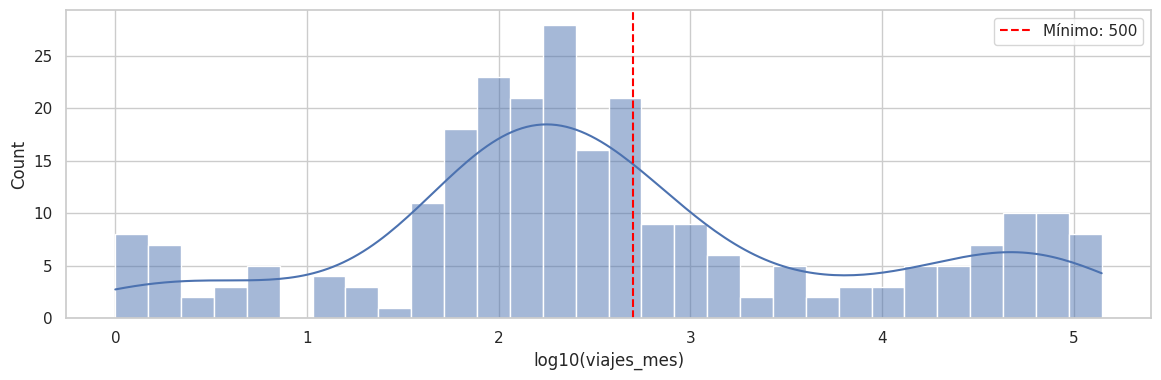

In [62]:
MIN_VIAJES_MES=500
viajes_mes = (df.groupby("PULocationID").size()
                .rename("viajes_mes").reset_index())

print("Zonas con viajes:", len(viajes_mes))

# Distribución con el umbral marcado
sns.histplot(np.log10(viajes_mes["viajes_mes"]), bins=30, kde=True)
plt.axvline(np.log10(MIN_VIAJES_MES), color="red", linestyle="--",
            label=f"Mínimo: {MIN_VIAJES_MES}")
plt.xlabel("log10(viajes_mes)")
plt.legend()
plt.show()

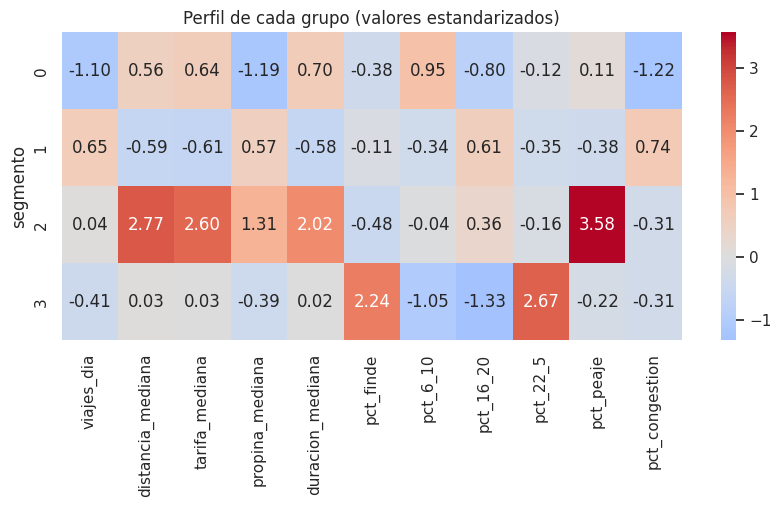

          viajes_dia  distancia_mediana  tarifa_mediana  propina_mediana  \
segmento                                                                   
0              29.55               3.62           22.50             0.00   
1            1396.84               1.61           12.10             2.66   
2             382.55              12.91           50.50            10.00   
3              67.71               2.86           18.05             1.22   

          duracion_mediana  pct_finde  pct_6_10  pct_16_20  pct_22_5  \
segmento                                                               
0                    16.65       0.24      0.31       0.21      0.17   
1                    11.04       0.26      0.17       0.33      0.15   
2                    32.38       0.22      0.15       0.34      0.17   
3                    14.91       0.44      0.10       0.16      0.57   

          pct_peaje  pct_congestion  
segmento                             
0              0.05            0.1

In [63]:
perfil_z = pd.DataFrame(X, columns=features).groupby(zonas["segmento"]).mean()

plt.figure(figsize=(10, 4))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de cada grupo (valores estandarizados)")
plt.show()

print(zonas.groupby("segmento")[ features].median().round(2))

In [64]:
from sklearn.decomposition import PCA

In [65]:
pca = PCA()
pca.fit(X)
pca.explained_variance_ratio_.round(3)

array([0.485, 0.214, 0.187, 0.044, 0.031, 0.015, 0.007, 0.007, 0.004,
       0.003, 0.002])

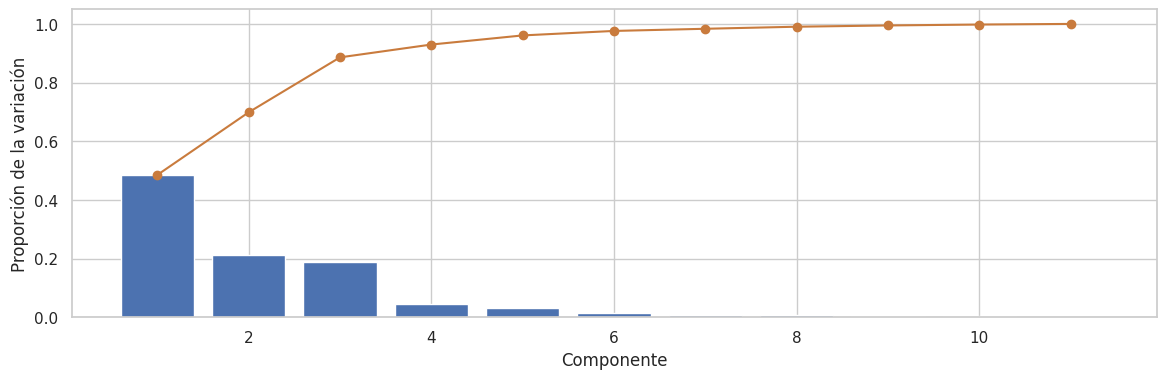

In [66]:
plt.bar(range(1, 12), pca.explained_variance_ratio_)
plt.plot(range(1, 12), pca.explained_variance_ratio_.cumsum(), marker="o", color="#C97B3D")
plt.xlabel("Componente")
plt.ylabel("Proporción de la variación")
plt.show()

In [67]:
cargas = pd.DataFrame(pca.components_[:2], columns=features, index=["Componente 1", "Componente 2"])
cargas.round(2)

,viajes_dia,distancia_mediana,tarifa_mediana,propina_mediana,duracion_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5,pct_peaje,pct_congestion
Componente 1,0.37,-0.36,-0.37,0.29,-0.38,0.08,-0.25,0.30,-0.07,-0.22,0.40
Componente 2,-0.17,-0.19,-0.17,-0.28,-0.16,0.53,-0.15,-0.34,0.53,-0.29,-0.12


PC1: 48.5% | PC2: 21.4% | Total conservado: 69.9%


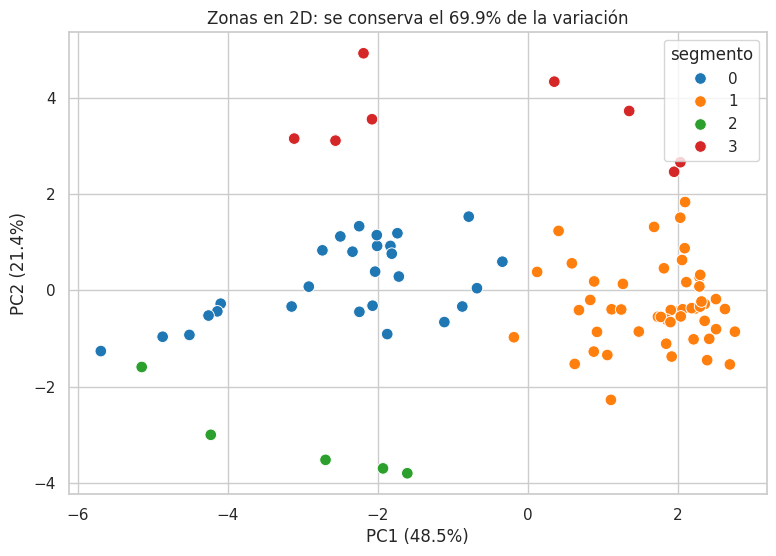

In [68]:

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
zonas["pc1"], zonas["pc2"] = coords[:, 0], coords[:, 1]

var = pca.explained_variance_ratio_
print(f"PC1: {var[0]:.1%} | PC2: {var[1]:.1%} | Total conservado: {var.sum():.1%}")

plt.figure(figsize=(9, 6))
sns.scatterplot(data=zonas, x="pc1", y="pc2", hue="segmento", palette="tab10", s=70)
plt.xlabel(f"PC1 ({var[0]:.1%})")
plt.ylabel(f"PC2 ({var[1]:.1%})")
plt.title(f"Zonas en 2D: se conserva el {var.sum():.1%} de la variación")
plt.show()

   k  silueta  davies_bouldin  calinski_harabasz
0  2    0.414           1.102             58.732
1  3    0.438           0.915             52.257
2  4    0.445           0.885             51.978
3  5    0.436           0.849             51.681
4  6    0.416           0.785             52.689
5  7    0.409           0.802             54.703


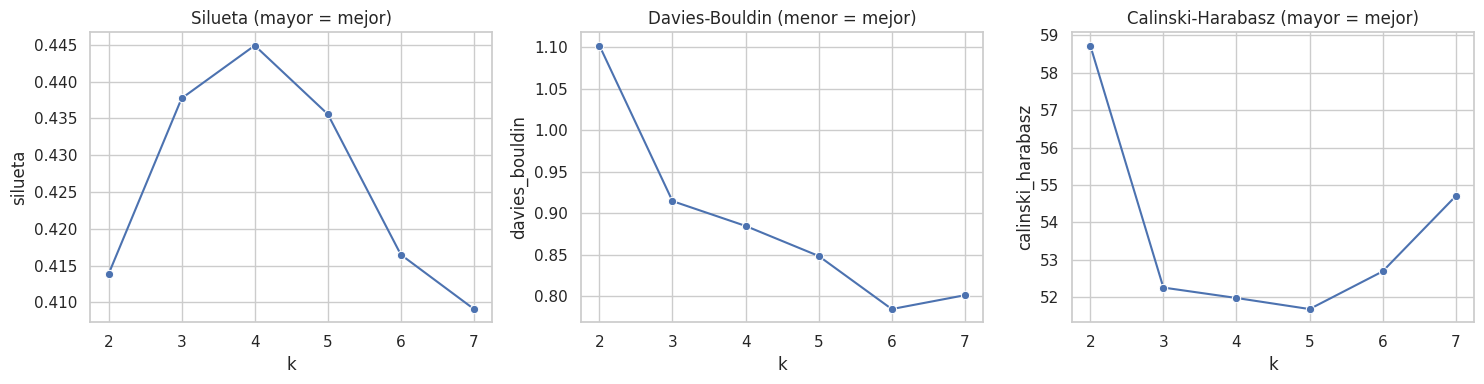

In [69]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

res = []
for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    res.append({
        "k": k,
        "silueta": silhouette_score(X, labels),            # mayor es mejor
        "davies_bouldin": davies_bouldin_score(X, labels), # menor es mejor
        "calinski_harabasz": calinski_harabasz_score(X, labels),  # mayor es mejor
    })

metricas = pd.DataFrame(res)
print(metricas.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes,
        ["silueta", "davies_bouldin", "calinski_harabasz"],
        ["Silueta (mayor = mejor)", "Davies-Bouldin (menor = mejor)", "Calinski-Harabasz (mayor = mejor)"]):
    sns.lineplot(data=metricas, x="k", y=col, marker="o", ax=ax)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

In [70]:
resultado = zonas.merge(
    df_zonas[["LocationID", "Borough", "Zone"]],
    left_on="PULocationID", right_on="LocationID", how="left"
)

In [71]:
for seg in sorted(resultado["segmento"].unique()):
    sub = resultado[resultado["segmento"] == seg].sort_values(['LocationID',"Borough", "Zone"])
    print(f"\n=== Segmento {seg} ({len(sub)} zonas) ===")
    display(sub[["LocationID","Borough", "Zone"]].reset_index(drop=True))


=== Segmento 0 (27 zonas) ===


,LocationID,Borough,Zone
0,7,Queens,Astoria
1,25,Brooklyn,Boerum Hill
2,33,Brooklyn,Brooklyn Heights
3,39,Brooklyn,Canarsie
4,42,Manhattan,Central Harlem North
5,61,Brooklyn,Crown Heights North
6,65,Brooklyn,Downtown Brooklyn/MetroTech
7,66,Brooklyn,DUMBO/Vinegar Hill
8,74,Manhattan,East Harlem North
9,76,Brooklyn,East New York



=== Segmento 1 (50 zonas) ===


,LocationID,Borough,Zone
0,12,Manhattan,Battery Park
1,13,Manhattan,Battery Park City
2,24,Manhattan,Bloomingdale
3,41,Manhattan,Central Harlem
4,43,Manhattan,Central Park
5,45,Manhattan,Chinatown
6,48,Manhattan,Clinton East
7,50,Manhattan,Clinton West
8,68,Manhattan,East Chelsea
9,75,Manhattan,East Harlem South



=== Segmento 2 (5 zonas) ===


,LocationID,Borough,Zone
0,10,Queens,Baisley Park
1,70,Queens,East Elmhurst
2,132,Queens,JFK Airport
3,138,Queens,LaGuardia Airport
4,215,Queens,South Jamaica



=== Segmento 3 (8 zonas) ===


,LocationID,Borough,Zone
0,4,Manhattan,Alphabet City
1,79,Manhattan,East Village
2,80,Brooklyn,East Williamsburg
3,112,Brooklyn,Greenpoint
4,114,Manhattan,Greenwich Village South
5,148,Manhattan,Lower East Side
6,255,Brooklyn,Williamsburg (North Side)
7,256,Brooklyn,Williamsburg (South Side)


In [72]:
zonas.head()

,PULocationID,n_viajes,n_dias,distancia_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5,...,pasajeros_medio,pct_peaje,pct_congestion,pct_tarjeta,pct_misma_zona,propina_pct_mediana,viajes_dia,segmento,pc1,pc2
0,4,3246,31,2.080,14.2,2.44,0.553913,0.126617,0.130314,0.599199,...,1.371851,0.007394,0.738139,0.664510,0.016020,0.254237,104.709677,3,0.349833,4.330016
1,7,1497,31,2.960,18.5,0.00,0.332665,0.307281,0.211757,0.195725,...,1.207129,0.049432,0.189045,0.353373,0.128925,0.197183,48.290323,0,-1.740216,1.183205
2,10,858,31,14.185,70.0,5.00,0.228438,0.275058,0.287879,0.170163,...,1.366093,0.463869,0.439394,0.780886,0.033800,0.142857,27.677419,2,-4.226642,-3.001566
3,12,846,31,4.600,24.7,2.97,0.263593,0.061466,0.289598,0.024823,...,1.748489,0.029551,0.969267,0.685579,0.004728,0.231462,27.290323,1,-0.188137,-0.975999
4,13,15310,31,3.510,19.8,3.65,0.172698,0.159895,0.427694,0.044481,...,1.332773,0.049706,0.922469,0.820118,0.020248,0.243478,493.870968,1,1.104006,-2.276468


In [73]:
nombres_grupos = {

    0: "Periferia de baja demanda",
    1: "Manhattan Central",
    2: "Largas distancias y Aeropuertos",
    3: "Barrios de Bares",

}

descripciones_grupos = {
    0: "Pocos viajes por día y propinas bajas; además viajes largos, sobre todo en la mañana.",
    1: "Alto volumen de viajes cortos, núcleo congestionado y con propinas superior al promedio.",
    2: "Viajes largos con tarifa y propina altas como Aeropuertos.",
    3: "Uso frecuente nocturno y de fin de semana.",

}

zonas["nombres_grupos"] = zonas["segmento"].map(nombres_grupos)
zonas["descripciones_grupos"] = zonas["segmento"].map(descripciones_grupos)
zonas = zonas.rename(columns={"segmento": "grupo"})

In [74]:
#Unión para ficha modelo
y = test["viajes"].to_numpy()
p10, p50, p90 = pred[:, i10], pred[:, i50], pred[:, i90]


mae = {
    "modelo": float(np.mean(np.abs(y - p50))),
    "hace_una_semana": float(np.mean(np.abs(y - test["lag_168"]))),
    "ayer": float(np.mean(np.abs(y - test["lag_24"]))),
}
mejora_vs_semana = (1 - mae["modelo"] / mae["hace_una_semana"]) * 100

# Cobertura del rango 10%-90%
cobertura = float(np.mean((y >= p10) & (y <= p90)))


GRUPOS = zonas[["PULocationID", "grupo"]]
t = test[["PULocationID"]].copy()
t["err_modelo"] = np.abs(y - p50)
t["err_semana"] = np.abs(y - test["lag_168"].to_numpy())
t["dentro"] = (y >= p10) & (y <= p90)
t = t.merge(GRUPOS, on="PULocationID", how="left")

por_grupo = (t.groupby("grupo")
               .agg(zonas=("PULocationID", "nunique"),
                    mae_modelo=("err_modelo", "mean"),
                    mae_semana=("err_semana", "mean"),
                    cobertura=("dentro", "mean"))
               .reset_index())

ficha = {
    "mae": mae,
    "mejora_vs_semana_pct": float(mejora_vs_semana),
    "cobertura_80": cobertura,
    "n_zonas": int(test["PULocationID"].nunique()),
    "n_filas_prueba": int(len(test)),
    "entrenamiento": {"desde": str(train["timestamp"].min()),
                      "hasta": str(train["timestamp"].max())},
    "prueba": {"desde": str(test["timestamp"].min()),
               "hasta": str(test["timestamp"].max())},
}

with open("ficha_modelo.json", "w", encoding="utf-8") as f:
    json.dump(ficha, f, ensure_ascii=False, indent=2)
por_grupo.to_csv("ficha_por_grupo.csv", index=False)

print(json.dumps(ficha, ensure_ascii=False, indent=2))
print(por_grupo.round(2).to_string(index=False))

{
  "mae": {
    "modelo": 11.597240114153534,
    "hace_una_semana": 11.881773399014778,
    "ayer": 21.286330049261085
  },
  "mejora_vs_semana_pct": 2.394703848541979,
  "cobertura_80": 0.8376436781609196,
  "n_zonas": 58,
  "n_filas_prueba": 9744,
  "entrenamiento": {
    "desde": "2024-01-08 01:00:00",
    "hasta": "2024-01-24 23:00:00"
  },
  "prueba": {
    "desde": "2024-01-25 00:00:00",
    "hasta": "2024-01-31 23:00:00"
  }
}
 grupo  zonas  mae_modelo  mae_semana  cobertura
     0      2        2.35        2.90       0.90
     1     49       11.75       11.94       0.83
     2      3       17.80       20.06       0.82
     3      4        9.67        9.54       0.86


In [75]:
NOMBRES = { 0: "Periferia de baja demanda",
            1: "Manhattan Central",
            2: "Largas distancias y Aeropuertos",
            3: "Barrios de Bares",}

t["viajes"] = y
por_grupo = (t.groupby("grupo")
               .agg(zonas=("PULocationID", "nunique"),
                    demanda_media=("viajes", "mean"),
                    mae_modelo=("err_modelo", "mean"),
                    mae_semana=("err_semana", "mean"),
                    cobertura=("dentro", "mean"))
               .reset_index())
por_grupo["error_relativo_pct"] = por_grupo["mae_modelo"] / por_grupo["demanda_media"] * 100
por_grupo["nombre_grupo"] = por_grupo["grupo"].map(NOMBRES)

por_grupo.to_csv("ficha_por_grupo.csv", index=False)
print(por_grupo.round(2).to_string(index=False))

 grupo  zonas  demanda_media  mae_modelo  mae_semana  cobertura  error_relativo_pct                    nombre_grupo
     0      2           6.18        2.35        2.90       0.90               37.94       Periferia de baja demanda
     1     49          73.10       11.75       11.94       0.83               16.08               Manhattan Central
     2      3         101.00       17.80       20.06       0.82               17.63 Largas distancias y Aeropuertos
     3      4          52.51        9.67        9.54       0.86               18.41                Barrios de Bares


In [ ]:

files.download("ficha_modelo.json")
files.download("ficha_por_grupo.csv")

In [76]:
zonas_csv = pd.read_csv(URL_ZONAS).set_index("LocationID")

In [77]:
# Índice con IDs reales
if "segmento" in zonas.columns:
    zonas = zonas.rename(columns={"segmento": "grupo"})
if "PULocationID" in zonas.columns:
    zonas = zonas.set_index("PULocationID")
zonas.index.name = "zona_id"
print("Columnas duplicadas:", zonas.columns.duplicated().sum())

Columnas duplicadas: 0


In [78]:
conteo = pd.crosstab(df["PULocationID"], df["hora"])
perfil_horario = conteo.div(conteo.sum(axis=1), axis=0)
perfil_horario = perfil_horario.reindex(columns=range(24), fill_value=0)
perfil_horario = perfil_horario.reindex(zonas.index, fill_value=0)
perfil_horario.index.name = "zona_id"
print("Zonas sin viajes en df:", (perfil_horario.sum(axis=1) == 0).sum())

# Comprobaciones
print("Forma:", perfil_horario.shape)
print("Suma por fila (min, max):", perfil_horario.sum(axis=1).min(), perfil_horario.sum(axis=1).max())
print("Zonas sin viajes en df:", (perfil_horario.sum(axis=1) == 0).sum())
perfil_horario.head()

Zonas sin viajes en df: 0
Forma: (90, 24)
Suma por fila (min, max): 0.9999999999999997 1.0000000000000004
Zonas sin viajes en df: 0


hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
zona_id,,,,,,,,,,,,,,,,,,,,,
4,0.110598,0.153112,0.127234,0.069624,0.018792,0.004929,0.011399,0.024338,0.035428,0.028959,...,0.021257,0.024646,0.021257,0.021873,0.025878,0.032964,0.028343,0.035120,0.040665,0.074245
7,0.018036,0.025384,0.016700,0.018036,0.042752,0.024716,0.050768,0.047428,0.080828,0.066800,...,0.054776,0.064796,0.062124,0.044088,0.038076,0.040080,0.027388,0.028724,0.018704,0.031396
10,0.022145,0.009324,0.002331,0.006993,0.004662,0.038462,0.074592,0.078089,0.053613,0.040793,...,0.060606,0.048951,0.104895,0.064103,0.027972,0.043124,0.047786,0.045455,0.051282,0.034965
12,0.005910,0.000000,0.001182,0.000000,0.001182,0.001182,0.000000,0.002364,0.016548,0.010638,...,0.140662,0.158392,0.153664,0.081560,0.024823,0.011820,0.017730,0.009456,0.010638,0.004728
13,0.004768,0.002417,0.000849,0.001437,0.001764,0.003527,0.008361,0.025539,0.044285,0.039647,...,0.071587,0.075049,0.079491,0.102874,0.107773,0.080732,0.056826,0.040300,0.019856,0.009863


In [79]:
for g, df_g in zonas.groupby("grupo"):
    top5 = df_g.sort_values("viajes_dia", ascending=False).head(5)
    print(g, nombres_grupos[g], "->", top5.index.map(zonas_csv["Zone"]).tolist())

0 Periferia de baja demanda -> ['East Harlem North', 'Central Harlem North', 'Sunnyside', 'Hamilton Heights', 'Manhattanville']
1 Manhattan Central -> ['Midtown Center', 'Upper East Side South', 'Upper East Side North', 'Midtown East', 'Times Sq/Theatre District']
2 Largas distancias y Aeropuertos -> ['JFK Airport', 'LaGuardia Airport', 'East Elmhurst', 'Baisley Park', 'South Jamaica']
3 Barrios de Bares -> ['East Village', 'Greenwich Village South', 'Lower East Side', 'Alphabet City', 'Williamsburg (North Side)']


In [80]:

# --- Tabla de zonas ---
tabla = zonas.copy()
tabla["nombre"] = tabla.index.map(zonas_csv["Zone"]).fillna("Desconocida")
tabla["distrito"] = tabla.index.map(zonas_csv["Borough"]).fillna("Desconocido")
tabla["nombre_grupo"] = tabla["grupo"].map(nombres_grupos)
tabla["descripcion"] = tabla["grupo"].map(descripciones_grupos)

X_esc = preparacion.transform(zonas[features])
coords = pca.transform(X_esc)
tabla["pc1"], tabla["pc2"] = coords[:, 0], coords[:, 1]

tabla.reset_index().to_csv("zonas_resumen.csv", index=False)
perfil_horario.reset_index().to_csv("perfil_horario.csv", index=False)

# Silueta para k = 2 a 7
silueta = {
    str(k): float(silhouette_score(
        X_esc, KMeans(k, n_init=10, random_state=42).fit_predict(X_esc)
    ))
    for k in range(2, 8)
}
json.dump(silueta, open("silueta.json", "w"))

# Descargar
for f in ["zonas_resumen.csv", "perfil_horario.csv", "silueta.json"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
#Guardar Modelo
import joblib
from google.colab import files

nombres_zonas = pd.read_csv(URL_ZONAS).set_index("LocationID")["Zone"]

joblib.dump(
    {"scaler": preparacion, "kmeans": km4},
    "modelo_zonas.joblib",
)

#Información Modelo
info_modelo = {
    "variables": list(features),
    "k": int(km4.n_clusters),
    "grupos": {
        int(g): {"nombre": nombres_grupos[g], "descripcion": descripciones_grupos[g]}
        for g in nombres_grupos
    },
    "zonas": {
        int(z): {
            "nombre": tabla.loc[z, "nombre"],
            "grupo": int(g),
            "nombre_grupo": nombres_grupos[g],
        }
        for z, g in zonas["grupo"].items()
    },
}

with open("info_modelo.json", "w", encoding="utf-8") as f:
    json.dump(info_modelo, f, ensure_ascii=False, indent=2)

# --- Descargar
files.download("modelo_zonas.joblib")
files.download("info_modelo.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile main.py
import json
from typing import List, Optional

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException, Query
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(title="API de segmentación de zonas de taxi")
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

# iniciar
modelo = joblib.load("modelo_zonas.joblib")
with open("info_modelo.json", encoding="utf-8") as f:
    info = json.load(f)
with open("silueta.json") as f:
    silueta = json.load(f)

zonas = pd.read_csv("zonas_resumen.csv").set_index("zona_id")
perfil = pd.read_csv("perfil_horario.csv").set_index("zona_id")
perfil.columns = range(24)

VARIABLES = info["variables"]


def filtrar(grupos: Optional[List[int]]):
    return zonas if not grupos else zonas[zonas["grupo"].isin(grupos)]


@app.get("/")
def raiz():
    return {"variables": VARIABLES, "k": info["k"]}


@app.get("/grupos")
def grupos():
    """Una tarjeta por grupo: zonas, viajes/día, distancia mediana, % de noche."""
    salida = []
    for g, df_g in zonas.groupby("grupo"):
        salida.append({
            "grupo": int(g),
            "nombre": info["grupos"][str(g)]["nombre"],
            "descripcion": info["grupos"][str(g)]["descripcion"],
            "n_zonas": int(len(df_g)),
            "viajes_dia": int(df_g["viajes_dia"].sum()),
            "distancia_mediana": round(float(df_g["distancia_mediana"].median()), 1),
            "pct_noche": round(float(df_g["pct_22_5"].mean()), 3),
        })
    return salida


@app.get("/puntos-pca")
def puntos_pca(grupos: Optional[List[int]] = Query(default=None)):
    df_p = filtrar(grupos).reset_index()
    return df_p[["zona_id", "nombre", "pc1", "pc2", "grupo", "nombre_grupo", "viajes_dia"]].to_dict("records")


@app.get("/zonas")
def tabla_zonas(grupos: Optional[List[int]] = Query(default=None), limite: int = 50):
    df_z = filtrar(grupos).sort_values("viajes_dia", ascending=False).head(limite)
    filas = []
    for zona_id, r in df_z.iterrows():
        filas.append({
            "zona_id": int(zona_id),
            "zona": r["nombre"],
            "distrito": r["distrito"],
            "grupo": int(r["grupo"]),
            "nombre_grupo": r["nombre_grupo"],
            "viajes_dia": int(r["viajes_dia"]),
            "distancia_mediana": round(float(r["distancia_mediana"]), 1),
            "pct_noche": round(float(r["pct_22_5"]), 4),
            "propina_mediana": round(float(r["propina_mediana"]), 2),
            "perfil_24h": [round(float(v), 4) for v in perfil.loc[zona_id].values],
        })
    return filas


@app.get("/zona/{zona_id}")
def detalle_zona(zona_id: int):
    if zona_id not in zonas.index:
        raise HTTPException(status_code=404, detail="Zona no encontrada")
    r = zonas.loc[zona_id]
    return {
        "zona_id": zona_id,
        "nombre": r["nombre"],
        "distrito": r["distrito"],
        "grupo": int(r["grupo"]),
        "nombre_grupo": r["nombre_grupo"],
        "descripcion": r["descripcion"],
    }


@app.get("/perfil-horario")
def perfil_horario(zona_ids: List[int] = Query(...)):
    faltan = [z for z in zona_ids if z not in perfil.index]
    if faltan:
        raise HTTPException(status_code=404, detail=f"Zonas sin perfil: {faltan}")
    return [
        {"zona_id": z, "zona": zonas.loc[z, "nombre"], "valores": [float(v) for v in perfil.loc[z].values]}
        for z in zona_ids
    ]


@app.get("/silueta")
def get_silueta():
    return silueta


@app.post("/predecir")
def predecir(datos: dict):
    faltantes = [v for v in VARIABLES if v not in datos]
    if faltantes:
        raise HTTPException(status_code=422, detail=f"Faltan variables: {faltantes}")
    X = pd.DataFrame([datos])[VARIABLES]
    grupo = int(modelo["kmeans"].predict(modelo["scaler"].transform(X))[0])
    g = info["grupos"][str(grupo)]
    return {"grupo": grupo, "nombre_grupo": g["nombre"], "descripcion": g["descripcion"]}

Writing main.py


In [ ]:
from google.colab import files

for f in ["main.py"]:
    files.download(f)

In [ ]:
import numpy, pandas, sklearn, joblib
from google.colab import files
requirements = f"""fastapi
uvicorn
requests
plotly
streamlit
pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print(requirements)
files.download("requirements.txt")

In [83]:
zonas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 90 entries, 4 to 263
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   n_viajes              90 non-null     int64  
 1   n_dias                90 non-null     int64  
 2   distancia_mediana     90 non-null     float64
 3   tarifa_mediana        90 non-null     float64
 4   propina_mediana       90 non-null     float64
 5   pct_finde             90 non-null     float64
 6   pct_6_10              90 non-null     float64
 7   pct_16_20             90 non-null     float64
 8   pct_22_5              90 non-null     float64
 9   duracion_mediana      90 non-null     float64
 10  velocidad_mediana     90 non-null     float64
 11  pasajeros_medio       90 non-null     float64
 12  pct_peaje             90 non-null     float64
 13  pct_congestion        90 non-null     float64
 14  pct_tarjeta           90 non-null     float64
 15  pct_misma_zona        90 non-

In [84]:
import requests
from google.colab import files

# Nombres y distritos de las zonas
info = requests.get("https://taxis-nyc.onrender.com/info", timeout=90).json()
nombres_zona = (pd.DataFrame(info["zonas"])
                  .rename(columns={"id": "PULocationID", "nombre": "zona"}))

por_zona = (t.groupby("PULocationID")
              .agg(grupo=("grupo", "first"),
                   demanda_media=("viajes", "mean"),
                   mae_modelo=("err_modelo", "mean"),
                   mae_semana=("err_semana", "mean"),
                   cobertura=("dentro", "mean"))
              .reset_index())
por_zona = por_zona.merge(nombres_zona, on="PULocationID", how="left")
por_zona["nombre_grupo"] = por_zona["grupo"].map(NOMBRES)
por_zona["gana_a_semana"] = por_zona["mae_modelo"] < por_zona["mae_semana"]

por_zona.to_csv("ficha_por_zona.csv", index=False)

# Resumen para redactar las limitaciones
print("Zonas:", len(por_zona), "| sin nombre:", int(por_zona["zona"].isna().sum()))
print("Cobertura por zona -> mínima: {:.0%} | máxima: {:.0%} | promedio: {:.0%}".format(
    por_zona["cobertura"].min(), por_zona["cobertura"].max(), por_zona["cobertura"].mean()))
print("Zonas con cobertura menor a 80%:", int((por_zona["cobertura"] < 0.8).sum()))
print("Zonas donde el modelo le gana a «hace una semana»:", int(por_zona["gana_a_semana"].sum()),
      "de", len(por_zona))

files.download("ficha_por_zona.csv")

Zonas: 58 | sin nombre: 0
Cobertura por zona -> mínima: 68% | máxima: 91% | promedio: 84%
Zonas con cobertura menor a 80%: 15
Zonas donde el modelo le gana a «hace una semana»: 43 de 58


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>